# Evaluación Sumativa 1. Análisis exploratorio e inferencial
## Dataset: weatherAUS (observaciones meteorológicas de Australia)

MCDI501: Estadística Computacional para la Toma de Decisiones

Este cuaderno conserva la estructura de la plantilla: preparación y calidad de los datos, análisis exploratorio, estimación de parámetros y pruebas de hipótesis. Se estudia la frecuencia de lluvia al día siguiente (`RainTomorrow`) y su relación con la temperatura, la humedad y la lluvia del día actual. Cada fila corresponde a una observación por fecha y localidad; no representa una persona ni una estación independiente de todas las demás.

Requisitos: Python, NumPy, pandas, SciPy, Matplotlib, IPython y Jupyter. Coloque `weatherAUS(1).csv` o `weatherAUS.csv` junto al notebook y ejecute las celdas en orden. Las figuras se guardan en `figuras_weatherAUS`.

## 0. Configuración y carga de datos

In [1]:
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
from IPython.display import display

SEED = 42
np.random.seed(SEED)

# Paleta y estilo propios del informe
INK   = '#2b2b2b'
TEAL  = '#2f6b76'
OCHRE = '#c0852f'
BRICK = '#a4503e'
STEM  = '#b9b0a2'
PANEL = '#f7f3ec'
GRIDC = '#ded6c8'
cmap_corr = LinearSegmentedColormap.from_list('teal_brick', [BRICK, '#efe7d9', TEAL])
cmap_corr.set_bad('white')

plt.rcParams.update({
    'figure.dpi':120, 'savefig.dpi':200, 'font.size':10, 'font.family':'serif',
    'figure.facecolor':'white', 'axes.facecolor':PANEL,
    'axes.edgecolor':'#9a9486', 'axes.linewidth':0.8,
    'axes.spines.top':False, 'axes.spines.right':False,
    'axes.titlesize':11, 'axes.titlelocation':'left', 'axes.titlepad':8,
    'text.color':INK, 'axes.labelcolor':INK, 'xtick.color':INK, 'ytick.color':INK,
})

def grid_h(ax):
    # grilla horizontal tenue por detras de los datos
    ax.set_axisbelow(True)
    ax.grid(axis='y', color=GRIDC, linewidth=0.7)
    ax.grid(axis='x', visible=False)

# Buscar el archivo local sin descargar otro dataset ni descartar columnas.
DATA_PATH = None  # Puede reemplazar None por una ruta explícita al CSV.
if DATA_PATH is None:
    candidatos = [carpeta / nombre for carpeta in (Path.cwd(), Path.cwd() / 'upload')
                  for nombre in ('weatherAUS(1).csv', 'weatherAUS.csv')]
    DATA_PATH = next((p for p in candidatos if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Coloque weatherAUS(1).csv o weatherAUS.csv junto al notebook, o defina DATA_PATH.')
df_raw = pd.read_csv(DATA_PATH)
requeridas = {'Date', 'Location', 'RainTomorrow', 'RainToday', 'MinTemp', 'MaxTemp', 'Rainfall', 'Humidity3pm'}
if not requeridas.issubset(df_raw.columns):
    raise ValueError(f'Faltan columnas: {requeridas - set(df_raw.columns)}')
df = df_raw.copy()
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
FIG_DIR = Path('figuras_weatherAUS')
FIG_DIR.mkdir(exist_ok=True)
print('Filas y columnas originales:', df_raw.shape)
print('Localidades:', df['Location'].nunique())
print('Período:', df['Date'].min(), 'a', df['Date'].max())
display(df.head())

Filas y columnas originales: (145460, 23)
Localidades: 49
Período: 2007-11-01 00:00:00 a 2017-06-25 00:00:00


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


## 1. Preparación y calidad de los datos

Antes de cualquier análisis revisamos la estructura, los tipos de variable, los datos faltantes, los
duplicados y los valores que parecen errores de captura.

In [2]:
# Estructura y tipos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Date           145460 non-null  datetime64[ns]
 1   Location       145460 non-null  object        
 2   MinTemp        143975 non-null  float64       
 3   MaxTemp        144199 non-null  float64       
 4   Rainfall       142199 non-null  float64       
 5   Evaporation    82670 non-null   float64       
 6   Sunshine       75625 non-null   float64       
 7   WindGustDir    135134 non-null  object        
 8   WindGustSpeed  135197 non-null  float64       
 9   WindDir9am     134894 non-null  object        
 10  WindDir3pm     141232 non-null  object        
 11  WindSpeed9am   143693 non-null  float64       
 12  WindSpeed3pm   142398 non-null  float64       
 13  Humidity9am    142806 non-null  float64       
 14  Humidity3pm    140953 non-null  float64       
 15  

In [3]:
n_original = len(df)
faltantes = pd.DataFrame({'Cantidad': df.isna().sum(), 'Porcentaje': df.isna().mean()*100})
display(faltantes.sort_values('Porcentaje', ascending=False).round(2))
print('Filas completamente duplicadas:', df.duplicated().sum())
print('Claves fecha/localidad duplicadas:', df.duplicated(['Date', 'Location']).sum())
print('Fechas no interpretables:', df['Date'].isna().sum())
for c in ['RainToday', 'RainTomorrow']:
    print(c, df[c].value_counts(dropna=False).to_dict())
    print('Etiquetas inesperadas:', df.loc[df[c].notna() & ~df[c].isin(['Yes', 'No']), c].unique())
controles = {}
for c in ['Humidity9am', 'Humidity3pm']:
    controles[c + ' fuera de [0,100]'] = int((df[c].notna() & ~df[c].between(0,100)).sum())
for c in ['Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm']:
    controles[c + ' negativo'] = int((df[c] < 0).sum())
for c in ['Cloud9am', 'Cloud3pm']:
    controles[c + ' fuera de [0,8]'] = int((df[c].notna() & ~df[c].between(0,8)).sum())
controles['MinTemp > MaxTemp'] = int((df['MinTemp'] > df['MaxTemp']).sum())
display(pd.Series(controles, name='Registros a revisar'))
for c in ['Rainfall', 'Evaporation', 'WindGustSpeed']:
    print(f'{c}: asimetría = {df[c].skew():.2f}; máximo = {df[c].max():.2f}')

,Cantidad,Porcentaje
Sunshine,69835,48.01
Evaporation,62790,43.17
Cloud3pm,59358,40.81
Cloud9am,55888,38.42
Pressure9am,15065,10.36
Pressure3pm,15028,10.33
WindDir9am,10566,7.26
WindGustDir,10326,7.10
WindGustSpeed,10263,7.06
Humidity3pm,4507,3.10


Filas completamente duplicadas: 0
Claves fecha/localidad duplicadas: 0
Fechas no interpretables: 0
RainToday {'No': 110319, 'Yes': 31880, nan: 3261}
Etiquetas inesperadas: []
RainTomorrow {'No': 110316, 'Yes': 31877, nan: 3267}
Etiquetas inesperadas: []


Humidity9am fuera de [0,100]    0
Humidity3pm fuera de [0,100]    0
Rainfall negativo               0
Evaporation negativo            0
Sunshine negativo               0
WindGustSpeed negativo          0
WindSpeed9am negativo           0
WindSpeed3pm negativo           0
Cloud9am fuera de [0,8]         2
Cloud3pm fuera de [0,8]         1
MinTemp > MaxTemp               0
Name: Registros a revisar, dtype: int64

Rainfall: asimetría = 9.84; máximo = 371.00
Evaporation: asimetría = 3.76; máximo = 145.00
WindGustSpeed: asimetría = 0.87; máximo = 135.00


**Decisiones de tratamiento.** Se conserva `df_raw` como copia original y se eliminan únicamente filas completamente duplicadas en la copia de trabajo. Las claves fecha/localidad repetidas se documentan; si existen registros distintos con la misma clave, se deben revisar antes de interpretarlos como observaciones independientes. Las fechas se convierten a formato temporal y las respuestas Yes/No se codifican como 1/0; los faltantes se conservan como tales.

No se imputa ni se elimina una fila por tener un faltante en cualquier columna. Cada estadística utiliza los casos disponibles para sus variables y muestra su tamaño muestral. Los valores fuera de rangos físicos básicos se marcan como faltantes; `MinTemp > MaxTemp` se deja señalado para revisión, sin decidir cuál medición sería errónea. No se eliminan temperaturas negativas ni extremos solo por su magnitud. La precipitación se muestra en escala logarítmica `log1p` para visualizar su asimetría sin recortar observaciones.

`RainTomorrow` es una etiqueta del dataset; no se reconstruye desplazando filas, pues hay múltiples localidades y pueden existir fechas discontinuas. El análisis describe los registros disponibles, no una muestra aleatoria representativa de toda Australia.

In [4]:
df = df.drop_duplicates().copy()
for c in ['Humidity9am', 'Humidity3pm']:
    df.loc[df[c].notna() & ~df[c].between(0,100), c] = np.nan
for c in ['Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm']:
    df.loc[df[c] < 0, c] = np.nan
for c in ['Cloud9am', 'Cloud3pm']:
    df.loc[df[c].notna() & ~df[c].between(0,8), c] = np.nan
for c in ['RainToday', 'RainTomorrow']:
    df[c] = df[c].where(df[c].isin(['Yes', 'No']))
df['lluvia_manana'] = df['RainTomorrow'].map({'No':0, 'Yes':1})
df['lluvia_hoy'] = df['RainToday'].map({'No':0, 'Yes':1})
n = len(df)
num_cols = df_raw.select_dtypes(include='number').columns.tolist()
print('Registros originales:', n_original, '| Registros de trabajo:', n)


Registros originales: 145460 | Registros de trabajo: 145460


## 2. Análisis exploratorio de datos

### 2.1 Estadística descriptiva

In [5]:
desc = df[num_cols].describe().T[['count','mean','50%','std','min','max']]
desc['skew'] = df[num_cols].skew()
desc.columns = ['n disponible','Media','Mediana','Desv. est.','Mínimo','Máximo','Asimetría']
display(desc.round(2))

,n disponible,Media,Mediana,Desv. est.,Mínimo,Máximo,Asimetría
MinTemp,143975.0,12.19,12.0,6.40,-8.5,33.9,0.02
MaxTemp,144199.0,23.22,22.6,7.12,-4.8,48.1,0.22
Rainfall,142199.0,2.36,0.0,8.48,0.0,371.0,9.84
Evaporation,82670.0,5.47,4.8,4.19,0.0,145.0,3.76
Sunshine,75625.0,7.61,8.4,3.79,0.0,14.5,-0.50
WindGustSpeed,135197.0,40.04,39.0,13.61,6.0,135.0,0.87
WindSpeed9am,143693.0,14.04,13.0,8.92,0.0,130.0,0.78
WindSpeed3pm,142398.0,18.66,19.0,8.81,0.0,87.0,0.63
Humidity9am,142806.0,68.88,70.0,19.03,0.0,100.0,-0.48
Humidity3pm,140953.0,51.54,52.0,20.80,0.0,100.0,0.03


### 2.2 Figura 1. Variable objetivo y datos faltantes

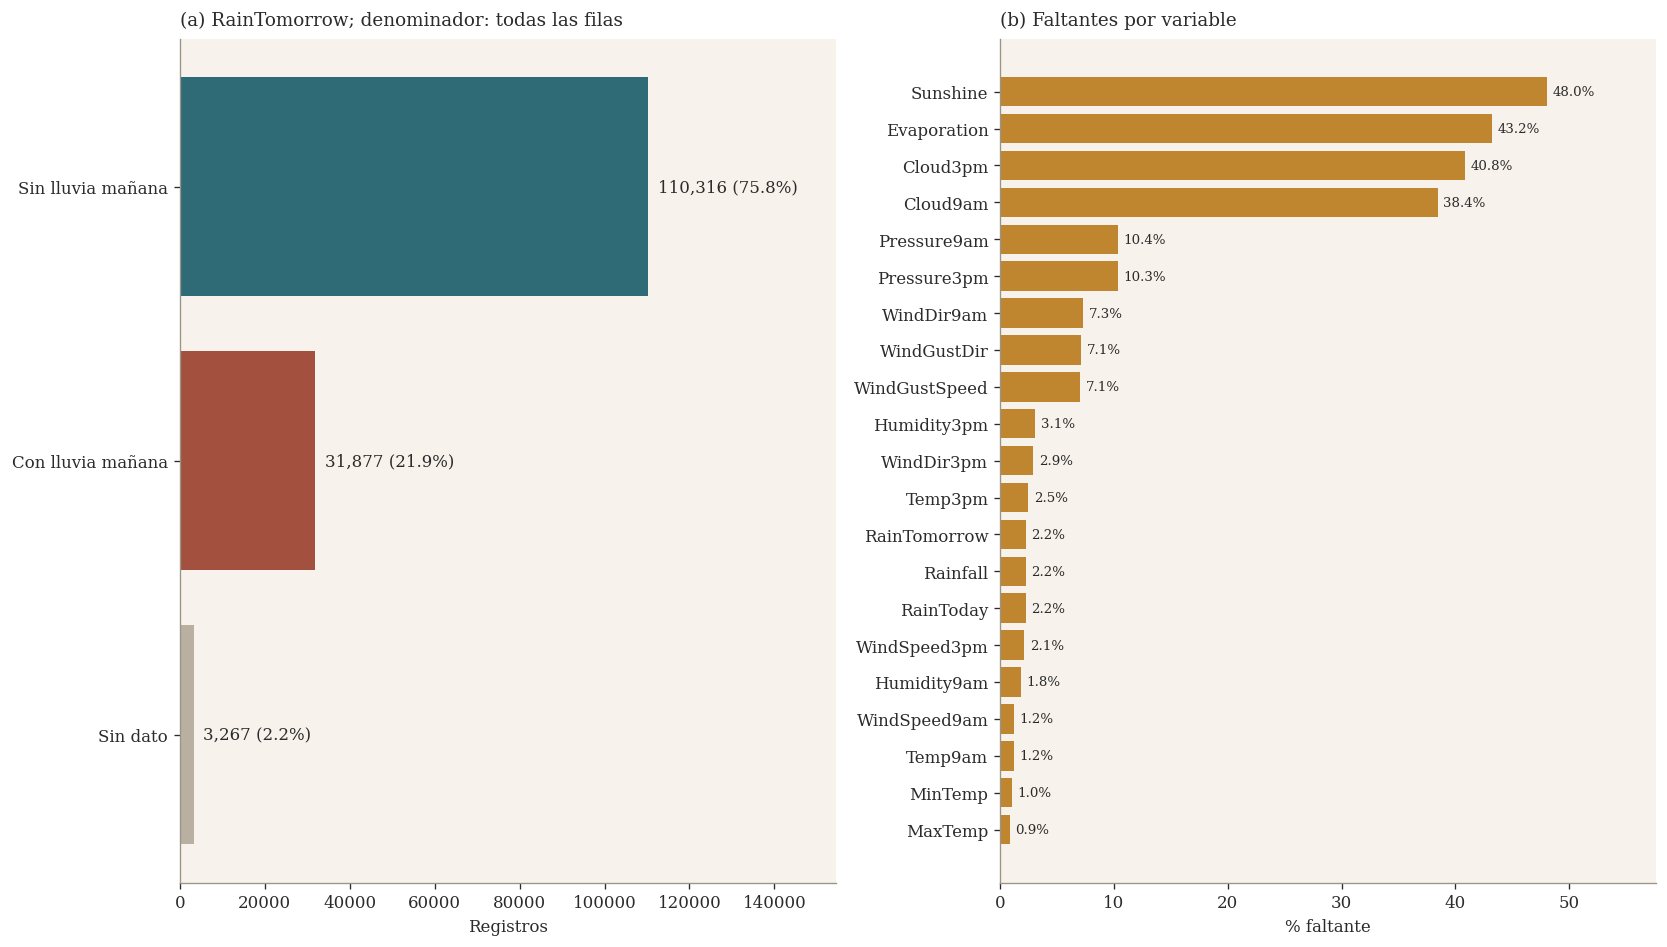

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 8))
vc = df['RainTomorrow'].fillna('Sin dato').value_counts().reindex(['No','Yes','Sin dato'], fill_value=0)
ax[0].barh(['Sin lluvia mañana', 'Con lluvia mañana', 'Sin dato'], vc.values, color=[TEAL,BRICK,STEM])
for i,v in enumerate(vc):
    ax[0].text(v+vc.max()*.02,i,f'{v:,} ({v/n*100:.1f}%)',va='center')
ax[0].set_xlim(0,vc.max()*1.4); ax[0].invert_yaxis()
ax[0].set_xlabel('Registros'); ax[0].set_title('(a) RainTomorrow; denominador: todas las filas')
miss = (df[df_raw.columns].isna().mean()*100).sort_values(ascending=False)
miss = miss[miss > 0]
ax[1].barh(miss.index,miss.values,color=OCHRE)
ax[1].invert_yaxis(); ax[1].set_xlabel('% faltante'); ax[1].set_title('(b) Faltantes por variable')
for i,v in enumerate(miss): ax[1].text(v+.5,i,f'{v:.1f}%',va='center',fontsize=8)
ax[1].set_xlim(0,max(1,miss.max())*1.2)
plt.tight_layout(); plt.savefig(FIG_DIR/'fig_panorama.png',bbox_inches='tight'); plt.show()

### 2.3 Figura 2. Distribución de variables numéricas

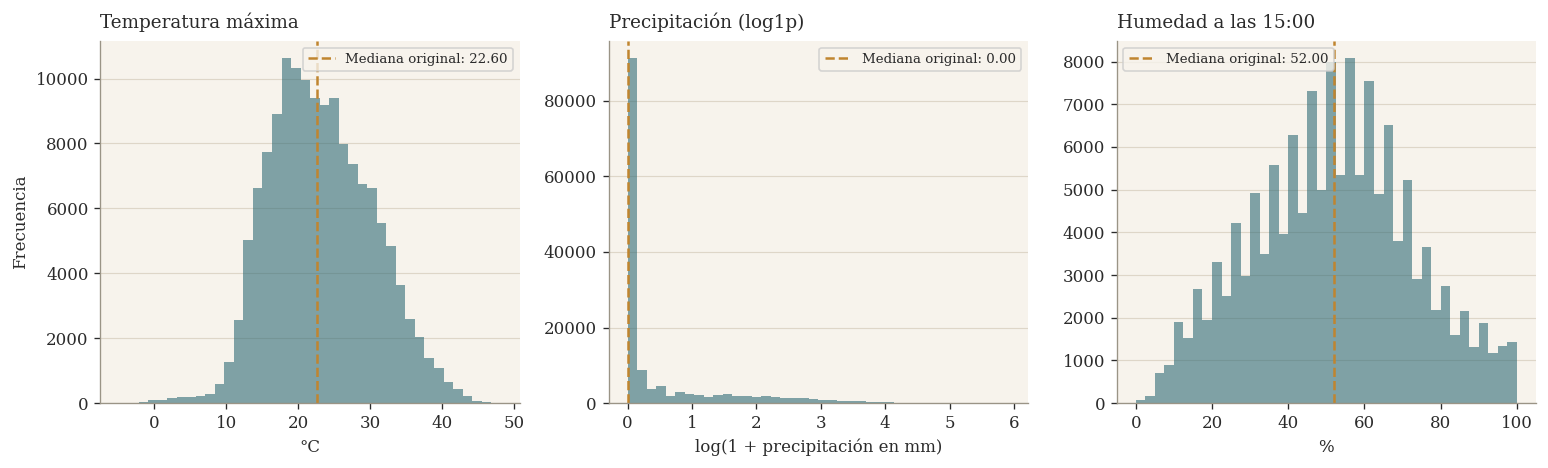

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a,c,titulo,unidad in zip(ax,['MaxTemp','Rainfall','Humidity3pm'],
                           ['Temperatura máxima','Precipitación (log1p)','Humedad a las 15:00'],
                           ['°C','log(1 + precipitación en mm)','%']):
    x = df[c].dropna()
    datos = np.log1p(x) if c == 'Rainfall' else x
    ref = np.log1p(x.median()) if c == 'Rainfall' else x.median()
    a.hist(datos,bins=40,color=TEAL,alpha=.6)
    a.axvline(ref,color=OCHRE,linestyle='--',label=f'Mediana original: {x.median():.2f}')
    a.set_title(titulo); a.set_xlabel(unidad); grid_h(a); a.legend(fontsize=8)
ax[0].set_ylabel('Frecuencia')
plt.tight_layout(); plt.savefig(FIG_DIR/'fig_distribuciones.png',bbox_inches='tight'); plt.show()

### 2.4 Figura 3. Matriz de correlaciones

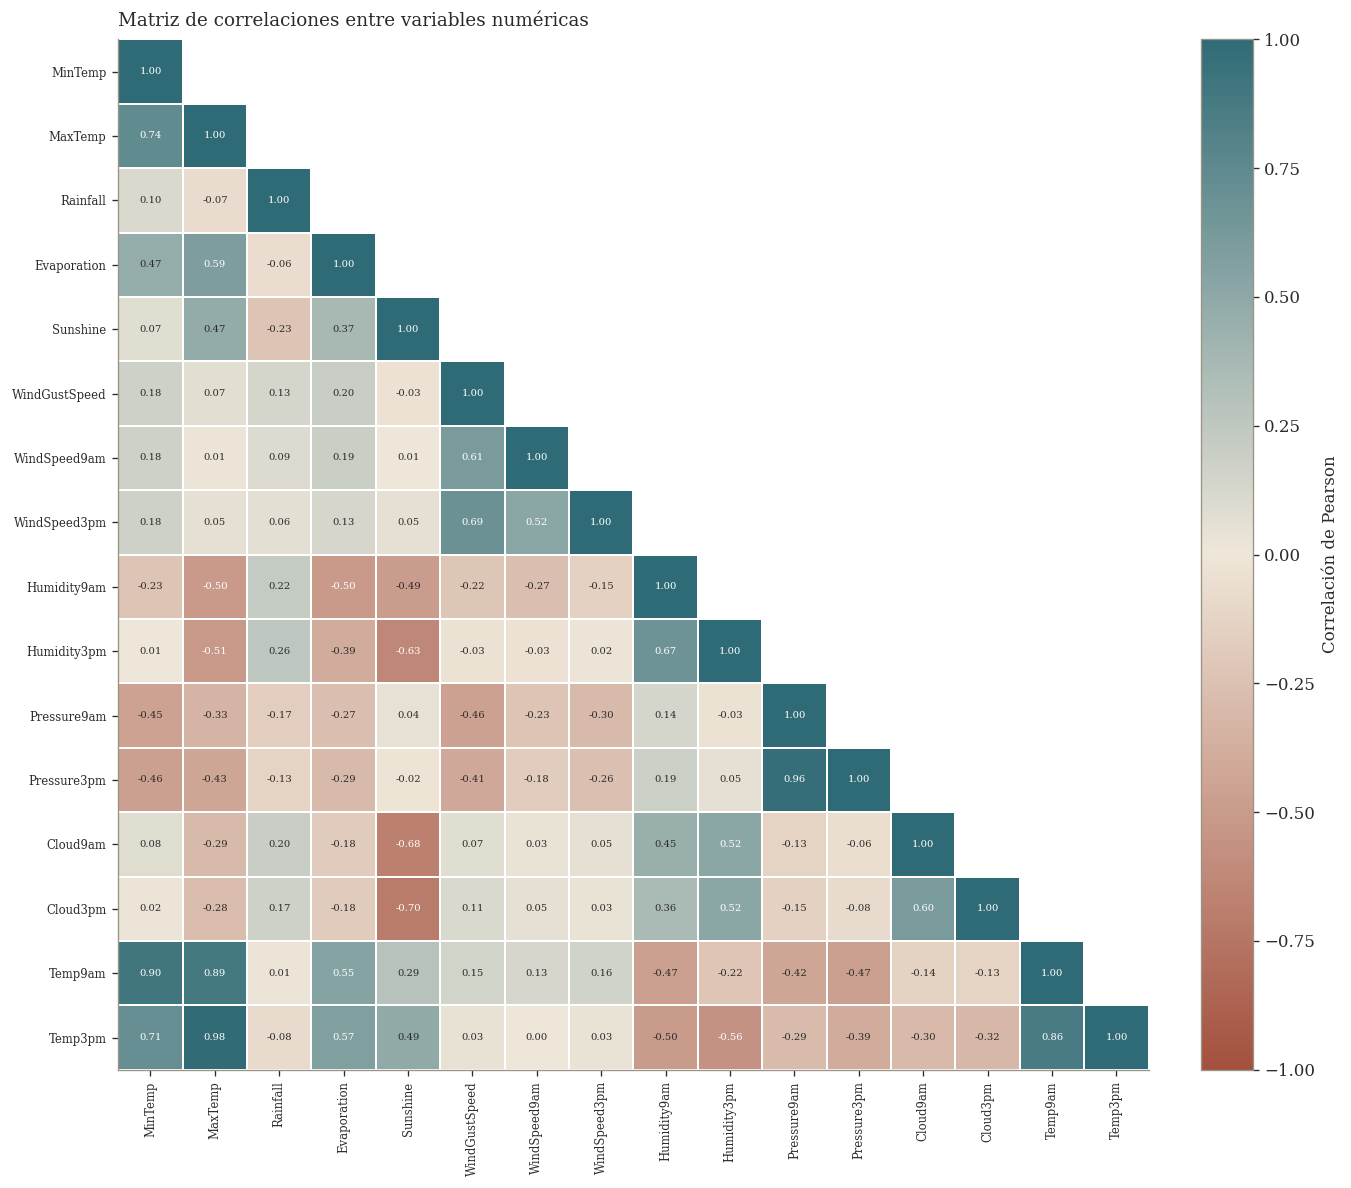

In [8]:
corr = df[num_cols].corr()
labels = [c[:22] for c in corr.columns]
M = np.ma.masked_array(corr.values, mask=np.triu(np.ones_like(corr.values, dtype=bool), k=1))

fig, ax = plt.subplots(figsize=(12, 10))
ax.set_facecolor('white')
im = ax.imshow(M, cmap=cmap_corr, vmin=-1, vmax=1)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=90, fontsize=7)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=7)
for i in range(len(corr)):
    for j in range(len(corr)):
        if j <= i:
            v = corr.values[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=6,
                    color='white' if abs(v) > 0.5 else INK)
ax.set_xticks(np.arange(-.5, len(labels), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(labels), 1), minor=True)
ax.grid(which='minor', color='white', linewidth=1.2); ax.tick_params(which='minor', length=0)
cb = fig.colorbar(im, fraction=0.046, pad=0.04); cb.set_label('Correlación de Pearson')
ax.set_title('Matriz de correlaciones entre variables numéricas')
plt.tight_layout(); plt.savefig(FIG_DIR/'fig_correlacion.png', bbox_inches='tight'); plt.show()

### 2.5 Análisis bivariado con variables derivadas

El dataset incluye categorías originales (localidad, direcciones del viento y lluvia actual). Se derivan el mes y los cuartiles de humedad a las 15:00 para comparar la proporción observada de lluvia al día siguiente. Los meses se interpretan en el hemisferio sur. Cada grupo excluye únicamente las observaciones sin categoría o sin respuesta; se informa su denominador. Estas asociaciones no implican causalidad ni controlan diferencias entre localidades.

In [9]:
df['mes'] = df['Date'].dt.month
# Los límites se obtienen de los cuantiles disponibles; duplicates evita límites repetidos.
df['cuartil_humedad'] = pd.qcut(df['Humidity3pm'], q=4, duplicates='drop')
gm = df['lluvia_manana'].mean()*100
print(f'Proporción global de lluvia mañana: {gm:.2f}% (n conocido = {df.lluvia_manana.count():,})')
def resumen_grupo(c):
    t = df.groupby(c,observed=True)['lluvia_manana'].agg(['count','sum','mean'])
    return t.rename(columns={'count':'n conocido','sum':'Días con lluvia','mean':'Proporción'}).assign(Porcentaje=lambda t:t['Proporción']*100)
for c in ['mes','cuartil_humedad','RainToday','Location']:
    print('\nLluvia mañana por',c)
    display(resumen_grupo(c).round(3))

Proporción global de lluvia mañana: 22.42% (n conocido = 142,193)

Lluvia mañana por mes


,n conocido,Días con lluvia,Proporción,Porcentaje
mes,,,,
1,12921,2498.0,0.193,19.333
2,10525,2207.0,0.210,20.969
3,13036,2781.0,0.213,21.333
4,11306,2463.0,0.218,21.785
5,13055,2941.0,0.225,22.528
6,12389,3244.0,0.262,26.185
7,11779,3171.0,0.269,26.921
8,11762,2970.0,0.253,25.251
9,11345,2606.0,0.230,22.970



Lluvia mañana por cuartil_humedad


,n conocido,Días con lluvia,Proporción,Porcentaje
cuartil_humedad,,,,
"(-0.001, 37.0]",36429,2172.0,0.060,5.962
"(37.0, 52.0]",34426,3660.0,0.106,10.631
"(52.0, 66.0]",35020,7361.0,0.210,21.019
"(66.0, 100.0]",32708,17720.0,0.542,54.176



Lluvia mañana por RainToday


,n conocido,Días con lluvia,Proporción,Porcentaje
RainToday,,,,
No,109332,16604.0,0.152,15.187
Yes,31455,14597.0,0.464,46.406



Lluvia mañana por Location


,n conocido,Días con lluvia,Proporción,Porcentaje
Location,,,,
Adelaide,3090,688.0,0.223,22.265
Albany,3016,902.0,0.299,29.907
Albury,3011,618.0,0.205,20.525
AliceSprings,3031,244.0,0.081,8.050
BadgerysCreek,2928,583.0,0.199,19.911
Ballarat,3028,781.0,0.258,25.793
Bendigo,3034,562.0,0.185,18.523
Brisbane,3161,709.0,0.224,22.430
Cairns,2988,950.0,0.318,31.794


### 2.6 Figura 4. Lluvia al día siguiente según mes y cuartil de humedad

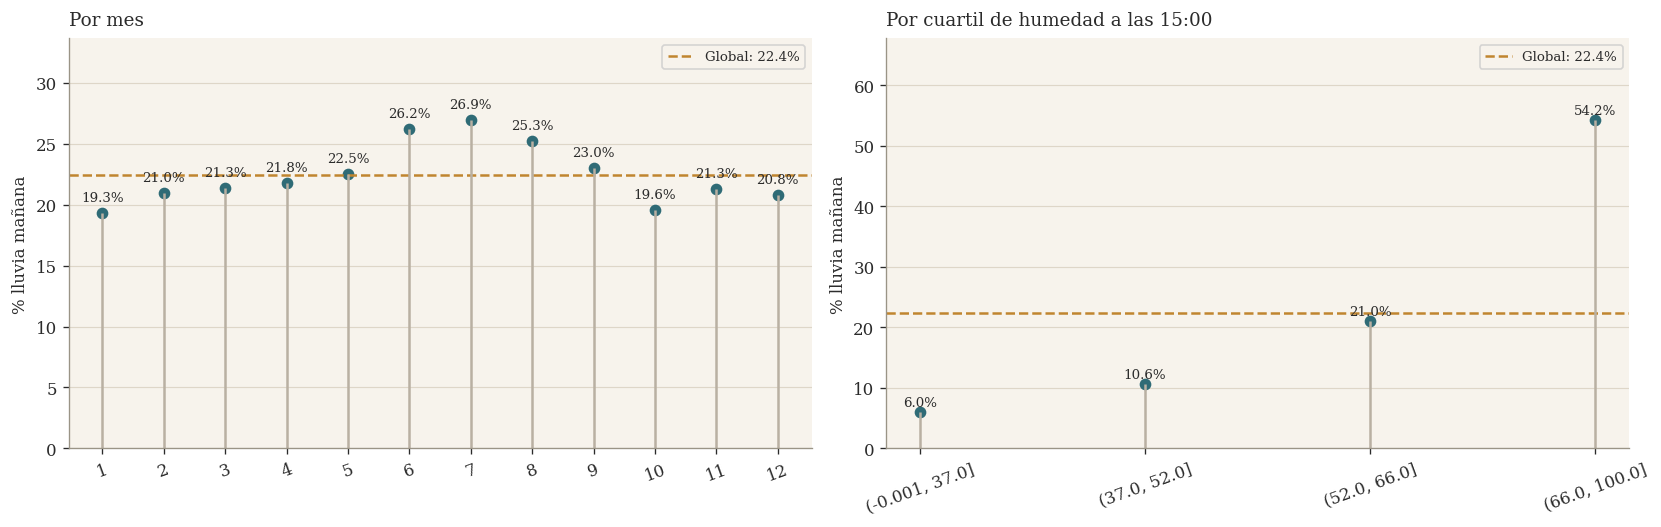

In [10]:
fig, ax = plt.subplots(1,2,figsize=(14,4.5))
for a,c,titulo in zip(ax,['mes','cuartil_humedad'],['Por mes','Por cuartil de humedad a las 15:00']):
    t = resumen_grupo(c)['Porcentaje']; xx = np.arange(len(t))
    a.axhline(gm,color=OCHRE,linestyle='--',label=f'Global: {gm:.1f}%')
    a.vlines(xx,0,t.values,color=STEM); a.scatter(xx,t.values,color=TEAL)
    for x,y in zip(xx,t): a.text(x,y+1,f'{y:.1f}%',ha='center',fontsize=8)
    a.set_xticks(xx); a.set_xticklabels(t.index.astype(str),rotation=20)
    a.set_title(titulo); a.set_ylabel('% lluvia mañana'); a.set_ylim(0,t.max()*1.25)
    grid_h(a); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR/'fig_bivariado.png',bbox_inches='tight'); plt.show()

## 3. Estimación de parámetros

Se estiman las medias de temperatura máxima (°C), precipitación (mm) y humedad a las 15:00 (%), además de la proporción de registros con lluvia al día siguiente. Se calculan intervalos al 95% mediante aproximación normal, siguiendo el procedimiento de la plantilla; el denominador es específico de cada variable.

**Alcance inferencial:** estos intervalos suponen observaciones independientes. La repetición diaria por localidad puede generar dependencia temporal y espacial; un tamaño grande no corrige ese problema. Por ello, se presentan como aproximaciones didácticas, no como cobertura garantizada para el clima australiano. Una inferencia formal requeriría definir la población y modelar la dependencia o remuestrear bloques temporales y localidades. Los faltantes también pueden sesgar las estimaciones.

In [11]:
z = stats.norm.ppf(0.975)
def ic_media(x):
    x = pd.Series(x).dropna()
    if len(x)<2: raise ValueError('Se requieren al menos dos observaciones.')
    m = x.mean(); se = x.std(ddof=1)/np.sqrt(len(x))
    return m,m-z*se,m+z*se,len(x)
def ic_prop(k,n):
    if n<=0: raise ValueError('Denominador vacío.')
    p=k/n; se=np.sqrt(p*(1-p)/n)
    return p,p-z*se,p+z*se
filas=[]
for c in ['MaxTemp','Rainfall','Humidity3pm']:
    m,lo,hi,nn=ic_media(df[c]); filas.append([c,nn,m,lo,hi])
intervalos = pd.DataFrame(filas,columns=['Variable','n','Media','IC95 inferior','IC95 superior'])
display(intervalos.round(4))
y = df['lluvia_manana'].dropna()
p_lluvia,lo,hi=ic_prop(y.sum(),len(y))
print(f'Lluvia mañana: {p_lluvia:.4%}; IC95% Wald [{lo:.4%}, {hi:.4%}]; n = {len(y):,}')

,Variable,n,Media,IC95 inferior,IC95 superior
0,MaxTemp,144199,23.2213,23.1846,23.2581
1,Rainfall,142199,2.3609,2.3169,2.4050
2,Humidity3pm,140953,51.5391,51.4306,51.6477


Lluvia mañana: 22.4181%; IC95% Wald [22.2014%, 22.6349%]; n = 142,193


## 4. Pruebas de hipótesis

### 4.1 Prueba 1. Presión atmosférica y lluvia al día siguiente (t de Welch)

Se analiza si la presión atmosférica media a las 15:00 (`Pressure3pm`,
medida en hPa) difiere entre los registros con y sin lluvia al día siguiente.

Las hipótesis son:

- **H₀:** la presión media es igual en ambos grupos:
  $\mu_{\text{Sí}} = \mu_{\text{No}}$.
- **H₁:** la presión media es diferente:
  $\mu_{\text{Sí}} \neq \mu_{\text{No}}$.

Se aplica una prueba bilateral t de Welch con un nivel de significancia
de 0,05, sin asumir igualdad de varianzas. Se utilizan únicamente los
registros con presión y respuesta conocidas. Se presentan los tamaños
muestrales, las medias, las desviaciones estándar y las asimetrías.

La diferencia de medias se calcula como presión con lluvia mañana menos
presión sin lluvia mañana. Un resultado negativo indica menor presión
media en el primer grupo. También se reporta d de Cohen como medida
descriptiva del tamaño del efecto.

La prueba supone observaciones independientes. La dependencia temporal
y espacial del dataset puede afectar el valor p, por lo que la inferencia
se interpreta como aproximada. Una diferencia significativa no demuestra
causalidad.

In [16]:
from scipy import stats
import numpy as np
import pandas as pd

ALPHA = 0.05

# Utilizar únicamente registros con presión y respuesta conocidas.
datos_presion = df.loc[
    df['RainTomorrow'].isin(['Yes', 'No']),
    ['Pressure3pm', 'RainTomorrow']
].dropna()

presion_si = datos_presion.loc[
    datos_presion['RainTomorrow'] == 'Yes', 'Pressure3pm'
]
presion_no = datos_presion.loc[
    datos_presion['RainTomorrow'] == 'No', 'Pressure3pm'
]

if min(len(presion_si), len(presion_no)) < 2:
    raise ValueError('Cada grupo necesita al menos dos registros.')

resumen_presion = pd.DataFrame({
    'Grupo': ['Con lluvia mañana', 'Sin lluvia mañana'],
    'n': [len(presion_si), len(presion_no)],
    'Media (hPa)': [presion_si.mean(), presion_no.mean()],
    'Desviación estándar': [presion_si.std(), presion_no.std()],
    'Asimetría': [presion_si.skew(), presion_no.skew()]
})

display(resumen_presion.round(3))

# Prueba bilateral de Welch: no supone varianzas iguales.
t_presion, p_presion = stats.ttest_ind(
    presion_si, presion_no, equal_var=False
)

diferencia_presion = presion_si.mean() - presion_no.mean()

# Tamaño del efecto descriptivo: d de Cohen.
n_si, n_no = len(presion_si), len(presion_no)
sd_combinada = np.sqrt(
    ((n_si - 1) * presion_si.var(ddof=1)
     + (n_no - 1) * presion_no.var(ddof=1))
    / (n_si + n_no - 2)
)
d_presion = (
    diferencia_presion / sd_combinada
    if sd_combinada > 0 else np.nan
)

p_texto = '< 0,001' if p_presion < 0.001 else f'= {p_presion:.4f}'

print(f'Estadístico t: {t_presion:.3f}')
print(f'Valor p: {p_texto}')
print(f'Diferencia de medias (Sí − No): {diferencia_presion:.3f} hPa')
print(f'd de Cohen: {d_presion:.3f}')

if p_presion < ALPHA:
    print('Se rechaza H₀ bajo los supuestos de la prueba.')
    print('Existe evidencia de una diferencia de presión media.')
else:
    print('No se rechaza H₀.')
    print('No hay evidencia suficiente de una diferencia de presión media.')

print(
    'La dependencia temporal y espacial puede afectar el valor p; '
    'esta comparación no demuestra causalidad.'
)

,Grupo,n,Media (hPa),Desviación estándar,Asimetría
0,Con lluvia mañana,28764,1012.301,7.332,-0.063
1,Sin lluvia mañana,99448,1016.114,6.710,0.052


Estadístico t: -79.132
Valor p: < 0,001
Diferencia de medias (Sí − No): -3.813 hPa
d de Cohen: -0.556
Se rechaza H₀ bajo los supuestos de la prueba.
Existe evidencia de una diferencia de presión media.
La dependencia temporal y espacial puede afectar el valor p; esta comparación no demuestra causalidad.


### Figura 5. Distribución de la presión atmosférica según lluvia al día siguiente

Los diagramas de caja comparan la presión a las 15:00 entre los registros
con y sin lluvia al día siguiente. La línea dentro de cada caja representa
la mediana y el rombo representa la media. Las cajas abarcan el 50 % central
de las observaciones.

Los puntos atípicos se ocultan para facilitar la visualización, pero se
conservan en el cálculo de las estadísticas y en la prueba de Welch.

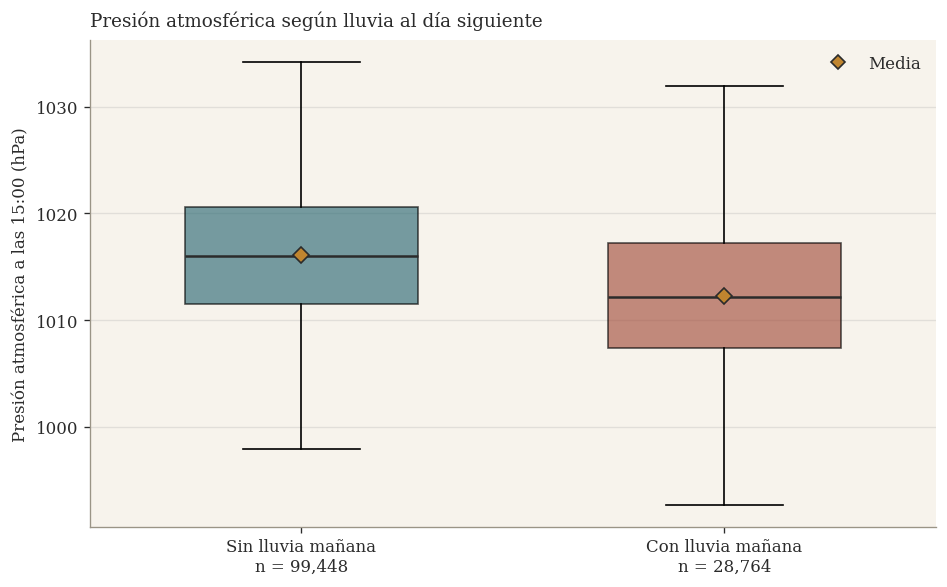

In [18]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

bp = ax.boxplot(
    [presion_no, presion_si],
    patch_artist=True,
    widths=0.55,
    showmeans=True,
    showfliers=False,
    meanprops={
        'marker': 'D',
        'markerfacecolor': '#c0852f',
        'markeredgecolor': '#2b2b2b',
        'markersize': 7
    },
    medianprops={
        'color': '#2b2b2b',
        'linewidth': 1.5
    }
)

for caja, color in zip(bp['boxes'], ['#2f6b76', '#a4503e']):
    caja.set_facecolor(color)
    caja.set_alpha(0.65)

ax.set_xticks([1, 2])
ax.set_xticklabels([
    f'Sin lluvia mañana\nn = {len(presion_no):,}',
    f'Con lluvia mañana\nn = {len(presion_si):,}'
])

ax.set_ylabel('Presión atmosférica a las 15:00 (hPa)')
ax.set_title('Presión atmosférica según lluvia al día siguiente')
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.3)

# Símbolo para identificar la media en la leyenda.
ax.plot(
    [], [], marker='D', linestyle='None',
    markerfacecolor='#c0852f',
    markeredgecolor='#2b2b2b',
    label='Media'
)
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig('fig_presion_lluvia.png', dpi=200, bbox_inches='tight')
plt.show()

### 4.2 Prueba 2. Velocidad de las ráfagas y lluvia al día siguiente (chi-cuadrado)

Se analiza si la velocidad de la ráfaga máxima (`WindGustSpeed`, medida
en km/h) está asociada con la lluvia al día siguiente (`RainTomorrow`).

Como la velocidad es numérica, se transforma en categorías mediante
cuartiles. Estos grupos ordenan los registros desde las velocidades más
bajas hasta las más altas. Sus límites se obtienen de los datos y no
corresponden a umbrales meteorológicos de intensidad. Los valores
repetidos pueden producir grupos de tamaños diferentes; si se repiten
los límites, el código puede generar menos de cuatro categorías.

Las hipótesis son:

- **H₀:** la categoría de velocidad y la lluvia al día siguiente son
  independientes.
- **H₁:** existe asociación entre ambas variables.

Se construye una tabla de contingencia con las categorías de velocidad
en las filas y las respuestas de lluvia al día siguiente en las columnas.
Se excluyen los registros sin velocidad válida o sin respuesta conocida.

Se aplica la prueba chi-cuadrado de Pearson con un nivel de significancia
de 0,05 y se verifica que todas las frecuencias esperadas sean al menos 5.
Se reporta V de Cramér para describir la magnitud de la asociación y el
porcentaje de lluvia al día siguiente en cada categoría.

Un resultado significativo indica una asociación global, pero no
identifica por sí solo qué categorías difieren entre sí ni demuestra
que exista una tendencia creciente. La categorización pierde parte de
la información numérica, y la dependencia temporal y espacial limita
la interpretación inferencial.

In [17]:
from scipy import stats
import numpy as np
import pandas as pd

ALPHA = 0.05

# Crear categorías usando las velocidades disponibles.
datos_viento = df[['WindGustSpeed', 'RainTomorrow']].copy()
datos_viento['WindGustSpeed'] = datos_viento['WindGustSpeed'].where(
    datos_viento['WindGustSpeed'] >= 0
)

datos_viento['cuartil_velocidad'] = pd.qcut(
    datos_viento['WindGustSpeed'],
    q=4,
    duplicates='drop'
)

# Excluir registros sin categoría o sin respuesta válida.
datos_viento = datos_viento.loc[
    datos_viento['RainTomorrow'].isin(['Yes', 'No'])
].dropna(subset=['cuartil_velocidad'])

# Los intervalos muestran los límites reales en km/h.
tabla_viento = pd.crosstab(
    datos_viento['cuartil_velocidad'],
    datos_viento['RainTomorrow']
).reindex(columns=['No', 'Yes'], fill_value=0)

if tabla_viento.shape[0] < 2 or (tabla_viento.sum(axis=0) == 0).any():
    raise ValueError('Se necesitan al menos dos grupos y ambas respuestas.')

print('Tabla de contingencia: intervalos de velocidad en km/h')
display(tabla_viento)

chi2_viento, p_viento, gl_viento, esperadas = (
    stats.chi2_contingency(tabla_viento, correction=False)
)

n_viento = tabla_viento.to_numpy().sum()
v_cramer = np.sqrt(
    chi2_viento
    / (n_viento * (min(tabla_viento.shape) - 1))
)

supuesto_cumplido = bool((esperadas >= 5).all())

print(f'Registros utilizados: {n_viento:,}')
print(f'Frecuencia esperada mínima: {esperadas.min():.2f}')
print(f'Todas las frecuencias esperadas ≥ 5: {supuesto_cumplido}')
print(f'Chi-cuadrado: {chi2_viento:.3f}')
print(f'Grados de libertad: {gl_viento}')
print(
    'Valor p:',
    '< 0,001' if p_viento < 0.001 else f'= {p_viento:.4f}'
)
print(f'V de Cramér: {v_cramer:.3f}')

if not supuesto_cumplido:
    print('Hay frecuencias esperadas menores que 5; revisar la aproximación.')
elif p_viento < ALPHA:
    print('Se rechaza H₀ bajo los supuestos de la prueba.')
    print('Existe evidencia de asociación entre velocidad y lluvia mañana.')
else:
    print('No se rechaza H₀.')
    print('No hay evidencia suficiente de asociación.')

# Frecuencia de lluvia mañana en cada categoría.
resumen_viento = pd.DataFrame({
    'n conocido': tabla_viento.sum(axis=1),
    'Con lluvia mañana': tabla_viento['Yes'],
    '% lluvia mañana': (
        tabla_viento['Yes'] / tabla_viento.sum(axis=1) * 100
    )
})

display(resumen_viento.round(2))

Tabla de contingencia: intervalos de velocidad en km/h


RainTomorrow,No,Yes
cuartil_velocidad,,
"(5.999, 31.0]",34913,5784
"(31.0, 39.0]",27690,5753
"(39.0, 48.0]",22867,6510
"(48.0, 135.0]",18018,11388


Registros utilizados: 132,923
Frecuencia esperada mínima: 6505.36
Todas las frecuencias esperadas ≥ 5: True
Chi-cuadrado: 6648.982
Grados de libertad: 3
Valor p: < 0,001
V de Cramér: 0.224
Se rechaza H₀ bajo los supuestos de la prueba.
Existe evidencia de asociación entre velocidad y lluvia mañana.


,n conocido,Con lluvia mañana,% lluvia mañana
cuartil_velocidad,,,
"(5.999, 31.0]",40697,5784,14.21
"(31.0, 39.0]",33443,5753,17.20
"(39.0, 48.0]",29377,6510,22.16
"(48.0, 135.0]",29406,11388,38.73


## Síntesis de resultados

Se resume la proporción de registros con lluvia al día siguiente y los
resultados de las dos pruebas de hipótesis: la comparación de presión
atmosférica media mediante t de Welch y la asociación entre cuartiles
de velocidad de las ráfagas y lluvia al día siguiente mediante chi-cuadrado.

Se consideran tanto la significancia estadística como la magnitud de
las diferencias y asociaciones. Los resultados describen los registros
disponibles y no demuestran causalidad. La dependencia temporal y espacial,
junto con los datos faltantes, limita su generalización.

In [19]:
# Panorama general.
respuesta = df['RainTomorrow'].dropna()
respuesta = respuesta[respuesta.isin(['Yes', 'No'])]
proporcion_lluvia = respuesta.eq('Yes').mean()

print(
    f'Se analizaron {len(df):,} registros '
    f'de {df["Location"].nunique()} localidades.'
)
print(
    f'RainTomorrow conocido en {len(respuesta):,} registros; '
    f'lluvia al día siguiente: {proporcion_lluvia:.2%}.'
)

# Prueba 1: presión atmosférica.
print('\nPresión atmosférica a las 15:00:')
print(f'Con lluvia mañana: {presion_si.mean():.2f} hPa.')
print(f'Sin lluvia mañana: {presion_no.mean():.2f} hPa.')
print(f'Diferencia (Sí − No): {diferencia_presion:.2f} hPa.')
print(f'd de Cohen: {d_presion:.3f}.')

if p_presion < ALPHA:
    print(
        'Welch: se rechaza H₀ bajo los supuestos de la prueba; '
        'existe evidencia de una diferencia de medias.'
    )
else:
    print(
        'Welch: no se rechaza H₀; no hay evidencia suficiente '
        'de una diferencia de medias.'
    )

# Prueba 2: categorías de velocidad de las ráfagas.
print('\nVelocidad de la ráfaga máxima:')
print(f'V de Cramér: {v_cramer:.3f}.')

if not supuesto_cumplido:
    print(
        'Chi-cuadrado: hay frecuencias esperadas menores que 5; '
        'se requiere revisar la aproximación antes de concluir.'
    )
elif p_viento < ALPHA:
    print(
        'Chi-cuadrado: se rechaza H₀ bajo los supuestos de la prueba; '
        'existe evidencia de asociación con la lluvia mañana.'
    )
else:
    print(
        'Chi-cuadrado: no se rechaza H₀; '
        'no hay evidencia suficiente de asociación.'
    )

display(resumen_viento.round(2))

print(
    '\nLos resultados no demuestran causalidad. '
    'La dependencia temporal y espacial y los faltantes '
    'limitan la inferencia y la generalización.'
)

Se analizaron 145,460 registros de 49 localidades.
RainTomorrow conocido en 142,193 registros; lluvia al día siguiente: 22.42%.

Presión atmosférica a las 15:00:
Con lluvia mañana: 1012.30 hPa.
Sin lluvia mañana: 1016.11 hPa.
Diferencia (Sí − No): -3.81 hPa.
d de Cohen: -0.556.
Welch: se rechaza H₀ bajo los supuestos de la prueba; existe evidencia de una diferencia de medias.

Velocidad de la ráfaga máxima:
V de Cramér: 0.224.
Chi-cuadrado: se rechaza H₀ bajo los supuestos de la prueba; existe evidencia de asociación con la lluvia mañana.


,n conocido,Con lluvia mañana,% lluvia mañana
cuartil_velocidad,,,
"(5.999, 31.0]",40697,5784,14.21
"(31.0, 39.0]",33443,5753,17.20
"(39.0, 48.0]",29377,6510,22.16
"(48.0, 135.0]",29406,11388,38.73



Los resultados no demuestran causalidad. La dependencia temporal y espacial y los faltantes limitan la inferencia y la generalización.
